# VOQC vs Qiskit
Two circuits · two optimizers · two saved IBM backends. Logical metrics precede routing; compiled metrics follow the same hardware policy.

## 1. Settings

In [1]:
from pathlib import Path

ROOT = Path.cwd()
from helpers.comparison import load_inputs, input_summary, optimize, compile_results

CIRCUITS = ["tof_3", "qft_5"]
BACKENDS = ["Manila", "Lima"]
SEED = 0
QISKIT_LEVEL = 3
FORCE_OPTIMIZE = False
OUTPUT = ROOT / "outputs"
VOQC_HOME = ROOT.parent / "pyvoqc"


## 2. Inputs

In [2]:
inputs = load_inputs(CIRCUITS)
input_summary(inputs)

,Circuit,Qubits,gates,2Q,depth
0,tof_3,5,45,18,33
1,qft_5,5,348,33,162


## 3. Logical optimization
VOQC: `optimize_nam()`. Qiskit: level 3, seed 0. Both use `h/x/rz/cx` without connectivity constraints. Cached outputs are reused unless `FORCE_OPTIMIZE=True`.

In [3]:
optimized = optimize(
    inputs, voqc_home=VOQC_HOME,
    qiskit_level=QISKIT_LEVEL, force=FORCE_OPTIMIZE, output=OUTPUT,
)

tof_3 / VOQC: {'gates': 40, '2Q': 16, 'depth': 31}
tof_3 / Qiskit: {'gates': 44, '2Q': 18, 'depth': 33}
qft_5 / VOQC: {'gates': 57, '2Q': 33, 'depth': 36}
qft_5 / Qiskit: {'gates': 99, '2Q': 33, 'depth': 58}


## 4. Hardware compilation
Level 1 · SABRE · initial placement `[0,1,2,3,4]` · seed 0 only. Each compiled circuit is saved as readable QASM and QPY, with equivalence and QASM round-trip checks.

In [4]:
table = compile_results(inputs, optimized, backends=BACKENDS, seed=SEED, output=OUTPUT)

## 5. Comparison
Click a column header to sort; use the search boxes to filter. Default order: Circuit → Backend → Optimizer. Logical metrics use Nam gates; compiled metrics use each backend’s native gates. Both backends use CX. Shared logical cells are merged for adjacent rows of the same circuit and optimizer; sorting and filtering update the merging.

Charts below show compiled counts as bars and logical counts as dashed marks on each bar. Groups follow Circuit → Backend → Optimizer. Logical gates use the Nam basis; compiled gates use the backend basis.

In [ ]:
from helpers.comparison import show_comparison

show_comparison(table)

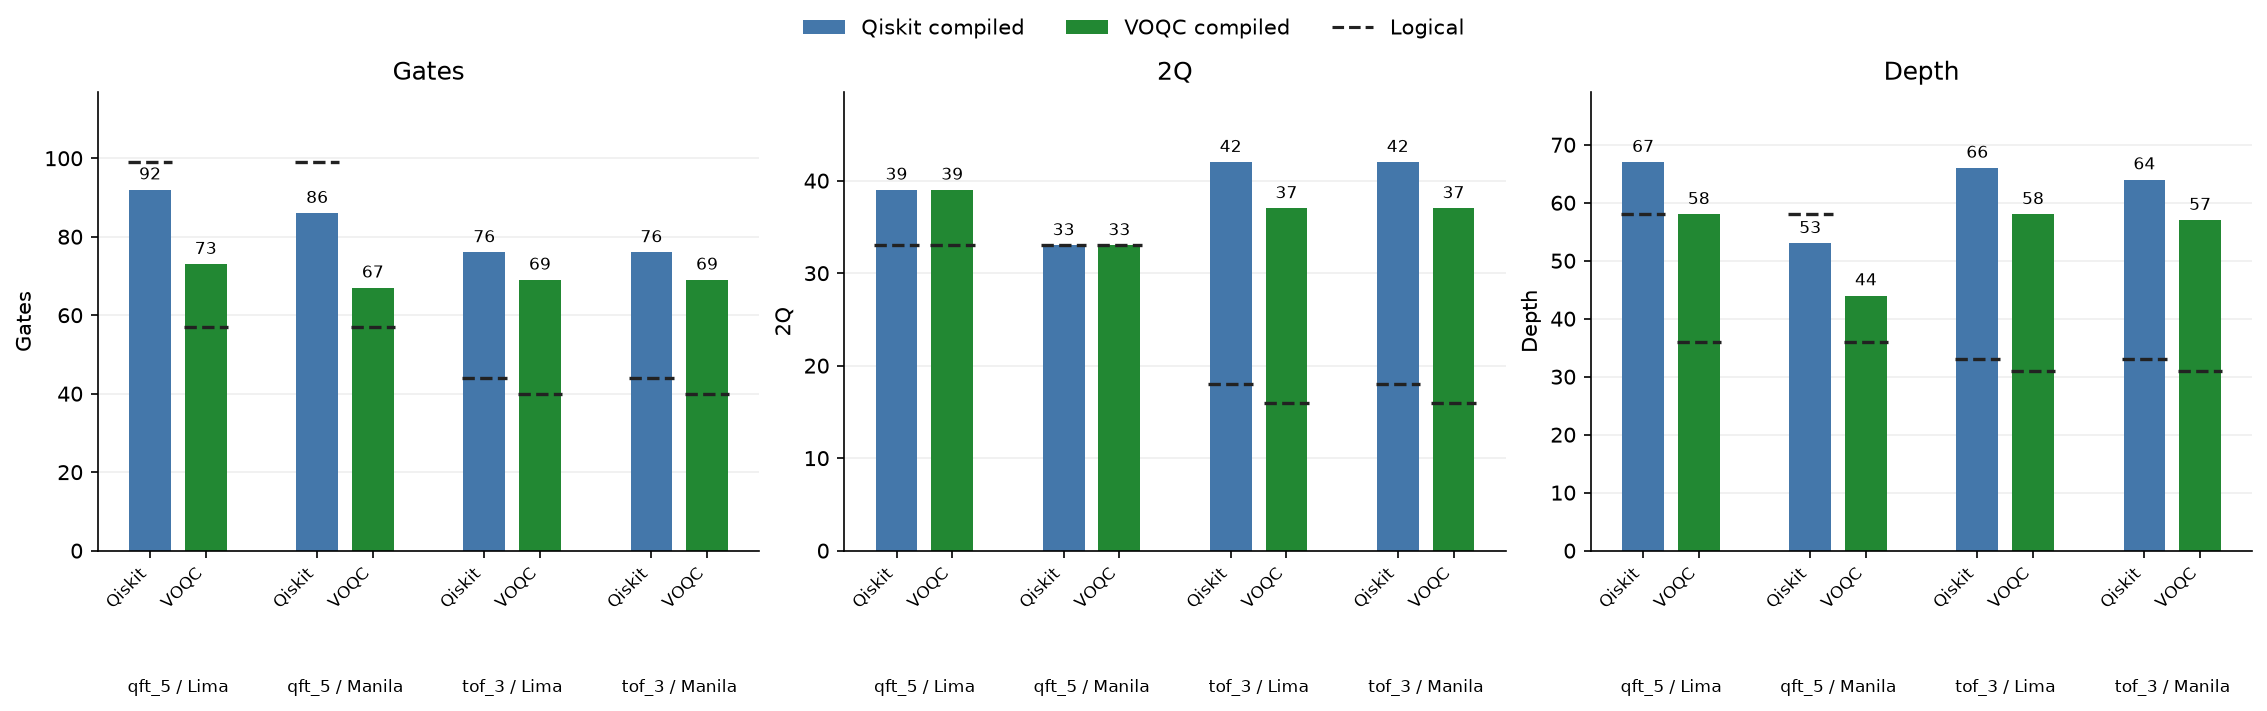

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plot_data = table.sort_values(["Circuit", "Backend", "Optimizer"]).reset_index(drop=True)
optimizers = list(plot_data["Optimizer"].drop_duplicates())
colors = dict(zip(optimizers, ["#4477AA", "#228833"]))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained")
for ax, metric in zip(axes, ["gates", "2Q", "depth"]):
    positions, tick_labels, group_centers = [], [], []
    cursor = 0
    for (circuit, backend), group in plot_data.groupby(["Circuit", "Backend"], sort=False):
        xs = list(range(cursor, cursor + len(group)))
        bars = ax.bar(xs, group[f"Compiled {metric}"],
                      color=[colors[o] for o in group["Optimizer"]], width=0.75)
        ax.bar_label(bars, padding=3, fontsize=8)
        # Each dashed segment marks that bar's logical metric, even above the bar.
        ax.hlines(group[f"Logical {metric}"], [x - 0.4 for x in xs],
                  [x + 0.4 for x in xs], colors="#222222", linestyles="--", linewidth=1.6)
        positions.extend(xs)
        tick_labels.extend(group["Optimizer"])
        group_centers.append((sum(xs) / len(xs), circuit, backend))
        cursor += len(group) + 1
    ax.set_xticks(positions, tick_labels, fontsize=8, rotation=45, ha="right")
    for center, circuit, backend in group_centers:
        ax.text(center, -0.28, f"{circuit} / {backend}",
                transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)
    ax.set_ylabel(metric.capitalize() if metric != "2Q" else "2Q")
    ax.set_title(metric.capitalize() if metric != "2Q" else "2Q")
    ax.set_ylim(0, plot_data[[f"Compiled {metric}", f"Logical {metric}"]].max().max() * 1.18)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
fig.legend(handles=[Patch(facecolor=colors[o], label=f"{o} compiled") for o in optimizers]
           + [Line2D([0], [0], color="#222222", linestyle="--", label="Logical")],
           loc="outside upper center", ncol=len(optimizers) + 1, frameon=False)
plt.show()


## 6. Controlled Qiskit workflows
Same two Nam input circuits and backends; seed 0, SABRE, placement `[0,1,2,3,4]`, exact synthesis. Compare direct backend L1, direct backend L3, and Nam logical L3 → backend L1. All numbers below describe the **final compiled circuit**; direct runs have no separate logical-output stage. Direct L3 changes downstream optimization effort as well as the pipeline.

In [6]:
from helpers.comparison import compare_workflows

controls = compare_workflows(inputs, backends=BACKENDS, seed=SEED, output=OUTPUT / "controls")

In [ ]:
from itables import show

show(
    controls, showIndex=False, classes="display compact", column_filters="header",
    paging=False, order=[[0, "asc"], [1, "asc"], [2, "asc"]],
    layout={"topStart": None, "topEnd": "search", "bottomStart": "info", "bottomEnd": None},
)


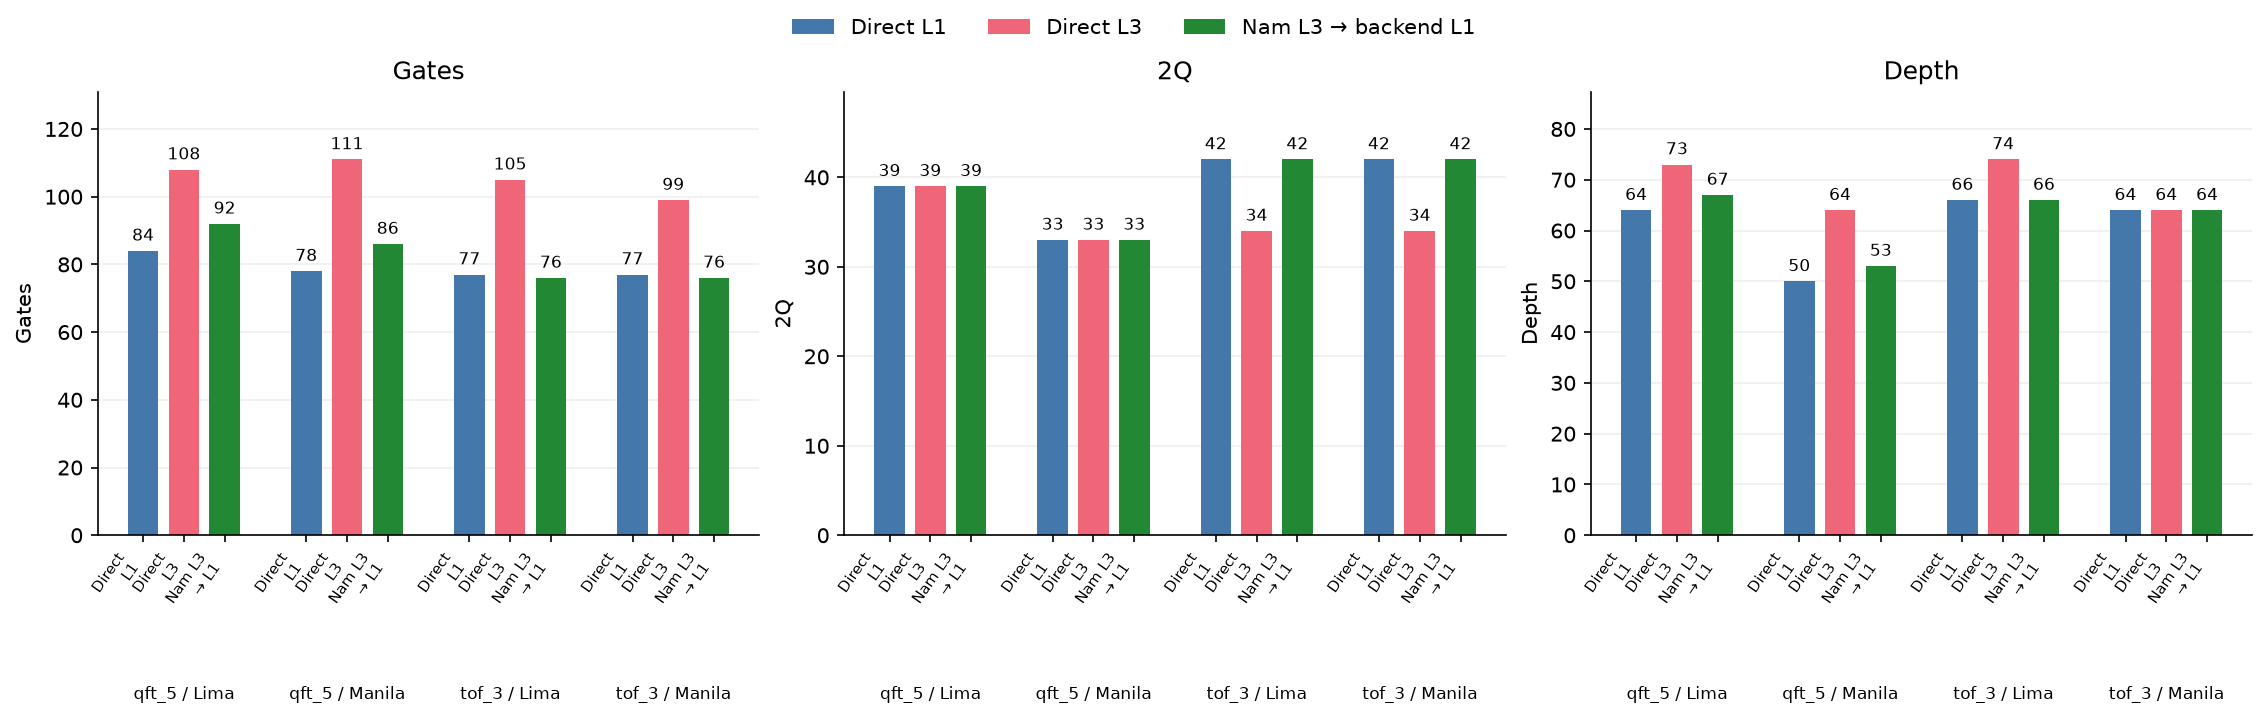

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Keep the table's Circuit → Backend → Workflow ordering.
plot_data = controls.sort_values(["Circuit", "Backend", "Workflow"]).reset_index(drop=True)
workflows = list(plot_data["Workflow"].drop_duplicates())
colors = dict(zip(workflows, ["#4477AA", "#EE6677", "#228833"]))
labels = {"Direct L1": "Direct\nL1", "Direct L3": "Direct\nL3",
          "Nam L3 → backend L1": "Nam L3\n→ L1"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained")
for ax, metric in zip(axes, ["Gates", "2Q", "Depth"]):
    positions, tick_labels = [], []
    group_centers = []
    cursor = 0
    for (circuit, backend), group in plot_data.groupby(["Circuit", "Backend"], sort=False):
        xs = list(range(cursor, cursor + len(group)))
        bars = ax.bar(xs, group[metric], color=[colors[w] for w in group["Workflow"]], width=0.75)
        ax.bar_label(bars, padding=3, fontsize=8)
        positions.extend(xs)
        tick_labels.extend(labels.get(w, w) for w in group["Workflow"])
        group_centers.append((sum(xs) / len(xs), circuit, backend))
        cursor += len(group) + 1
    ax.set_xticks(positions, tick_labels, fontsize=7, rotation=55, ha="right")
    for center, circuit, backend in group_centers:
        ax.text(center, -0.34, f"{circuit} / {backend}",
                transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.set_ylim(0, plot_data[metric].max() * 1.18)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
fig.legend(handles=[Patch(facecolor=colors[w], label=w) for w in workflows],
           loc="outside upper center", ncol=len(workflows), frameon=False)
plt.show()
